# Actividad 3.5 – Refinamiento técnico y optimización de hiperparámetros

## Continuación de la Actividad 3.4

En la actividad anterior desarrollaste un **Pipeline Integrado de Deep Learning** capaz de cargar datos, preprocesarlos, construir modelos MLP y CNN, incorporar técnicas de regularización, entrenar distintas configuraciones, evaluar su desempeño y realizar una auditoría mediante métricas tradicionales y herramientas de Explainable AI.

Durante dicha actividad comparaste distintas arquitecturas y configuraciones experimentales, identificando aquella que presentó el mejor desempeño general.

En esta actividad **no construirás un nuevo Pipeline**, ni volverás a comparar todas las arquitecturas implementadas anteriormente.

El objetivo consiste en **reutilizar el Pipeline Integrado desarrollado en la Actividad 3.4** para refinar el modelo seleccionado mediante el ajuste sistemático de sus hiperparámetros.

Para mantener la continuidad del proyecto, utilizarás como **modelo baseline** la **CNN regularizada** desarrollada durante la actividad anterior, ya que corresponde a la configuración que obtuvo el mejor desempeño durante la etapa de comparación.

---

## Objetivos de aprendizaje

Al finalizar esta actividad serás capaz de:

- Reutilizar un Pipeline Integrado previamente desarrollado para implementar nuevas etapas de optimización.
- Optimizar una red neuronal convolucional mediante el ajuste sistemático de hiperparámetros.
- Diseñar experimentos controlados modificando una única variable a la vez.
- Comparar distintas configuraciones utilizando métricas objetivas de desempeño.
- Analizar la robustez y capacidad de generalización del modelo optimizado.
- Justificar técnicamente la selección de la configuración final utilizando evidencia experimental.


# Parte I. Recordando el Pipeline Integrado

## El Pipeline desarrollado en la actividad anterior

Durante la Actividad 3.4 construiste un **Pipeline Integrado de Deep Learning**, organizando el desarrollo del modelo en distintas etapas que permitieron automatizar gran parte del flujo de trabajo.

Este pipeline constituye la base sobre la cual se desarrollará la presente actividad.

En esta oportunidad no construiremos un nuevo modelo desde cero. El objetivo consiste en continuar el proceso de desarrollo incorporando una nueva etapa: **la optimización de hiperparámetros**.

Antes de comenzar, recuerda la estructura general del pipeline implementado previamente.

```
Carga de datos

↓

Análisis exploratorio del dataset

↓

Preprocesamiento

↓

Construcción del modelo

↓

Entrenamiento

↓

Evaluación

↓

Explainable AI

↓

Reporte de resultados
```

Cada una de estas etapas cumple un propósito específico dentro del desarrollo de un sistema de Deep Learning.

Durante esta actividad nos concentraremos únicamente en **refinar el proceso de entrenamiento**, manteniendo la arquitectura seleccionada al finalizar la Actividad 3.4.

El objetivo ya no consiste en diseñar una nueva red neuronal, sino en estudiar cómo distintos **hiperparámetros** influyen sobre el comportamiento del modelo y su capacidad de generalización.

---

## Modelo de referencia

Para mantener una comparación experimental válida, se utilizará como punto de partida la **CNN regularizada** desarrollada durante la Actividad 3.4.

Esta arquitectura será considerada el **modelo baseline**, sobre el cual se realizarán los distintos experimentos de optimización.

La arquitectura permanecerá constante durante toda la actividad. Las diferencias observadas entre experimentos deberán deberse exclusivamente a las modificaciones realizadas sobre los hiperparámetros de entrenamiento.

---

## Funciones del Pipeline

A continuación se presentan las funciones que conforman el Pipeline Integrado.

Algunas corresponden a las implementadas durante la Actividad 3.4 y otras han sido adaptadas para facilitar el proceso de optimización desarrollado en esta actividad.

Antes de utilizarlas, revisa cuidadosamente el objetivo de cada una y analiza el rol que cumple dentro del Pipeline completo.


In [30]:
# Importar librerias recuerda antes instalrlas en tu ambiente de trabajo
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import sklearn
import os
import tensorflow.keras as keras


In [31]:
def cargar_datos():
    """
    Carga el dataset CIFAR-10.

    Returns
    -------
    x_train : numpy.ndarray
        Imágenes de entrenamiento.

    y_train : numpy.ndarray
        Etiquetas de entrenamiento.

    x_test : numpy.ndarray
        Imágenes de prueba.

    y_test : numpy.ndarray
        Etiquetas de prueba.

    class_names : list
        Nombre de las clases del dataset.
    """

    # ==========================================
    # Cargar dataset
    # ==========================================

    (x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

    # ==========================================
    # Definir nombres de las clases
    # ==========================================

    class_names = [
        "Airplane",
        "Automobile",
        "Bird",
        "Cat",
        "Deer",
        "Dog",
        "Frog",
        "Horse",
        "Ship",
        "Truck"
    ]

    # ==========================================
    # Mostrar información del dataset
    # ==========================================

    print("=" * 50)
    print("Dataset: CIFAR-10")
    print("=" * 50)

    print(f"Imágenes de entrenamiento : {x_train.shape}")
    print(f"Etiquetas entrenamiento   : {y_train.shape}")

    print()

    print(f"Imágenes de prueba        : {x_test.shape}")
    print(f"Etiquetas prueba          : {y_test.shape}")

    print()

    print(f"Número de clases          : {len(class_names)}")

    print("=" * 50)

    return x_train, y_train, x_test, y_test, class_names

In [32]:
def preprocesar(x_train, y_train, x_test, y_test):

    import tensorflow as tf
    from tensorflow.keras.utils import to_categorical

    # ==========================================================
    # Paso 1
    # Normalización
    # ==========================================================

    x_train = x_train.astype("float32") / 255.0
    x_test = x_test.astype("float32") / 255.0

    print("="*60)
    print("NORMALIZACIÓN")
    print("="*60)

    print(f"Valor mínimo entrenamiento : {x_train.min():.2f}")
    print(f"Valor máximo entrenamiento : {x_train.max():.2f}")

    # ==========================================================
    # Paso 2
    # One Hot Encoding
    # ==========================================================
    
    y_train = to_categorical(y_train)
    y_test = to_categorical(y_test)

    print("\n")
    print("="*60)
    print("ONE-HOT ENCODING")
    print("="*60)

    print(f"Shape etiquetas entrenamiento : {y_train.shape}")
    print(f"Shape etiquetas prueba        : {y_test.shape}")

    # ==========================================================
    # Paso 3
    # Data Augmentation
    # ==========================================================

    data_augmentation = tf.keras.Sequential([
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.10),
        tf.keras.layers.RandomZoom(0.10),
        tf.keras.layers.RandomTranslation(height_factor=0.10,width_factor=0.10)
    ])

    print("\n")
    print("="*60)
    print("DATA AUGMENTATION")
    print("="*60)

    data_augmentation.summary()

    # ==========================================================
    # Visualización de ejemplo
    # ==========================================================

    plt.figure(figsize=(10,3))

    imagen = x_train[0]

    for i in range(5):
        plt.subplot(1,5,i+1)
        imagen_aug = data_augmentation(tf.expand_dims(imagen,0),training=True)
        plt.imshow(imagen_aug[0])
        plt.axis("off")

    plt.tight_layout()
    plt.show()

    return (x_train,y_train,x_test,y_test,data_augmentation)


## Actualización de la función `construir_modelo()`

Durante la Actividad 3.4 esta función permitía construir distintas arquitecturas (MLP y CNN) con o sin regularización, ya que el objetivo consistía en comparar diferentes modelos.

En esta actividad el objetivo es diferente.

La arquitectura ya fue seleccionada y permanecerá fija durante todos los experimentos. A partir de este momento el interés se centra exclusivamente en estudiar cómo distintos **hiperparámetros** afectan el comportamiento del modelo.

Por esta razón la función ha sido adaptada para facilitar el proceso de optimización.

### Cambios incorporados

La nueva versión considera las siguientes modificaciones:

- Se elimina la construcción de múltiples arquitecturas y se mantiene únicamente la **CNN regularizada**, utilizada como modelo baseline.
- Los principales hiperparámetros del modelo pasan a definirse mediante parámetros de entrada de la función.
- El optimizador **Adam** permite modificar directamente el **Learning Rate**, facilitando su ajuste durante los experimentos.
- La arquitectura permanece constante durante toda la actividad, garantizando que las diferencias observadas se deban únicamente a los hiperparámetros evaluados.
- La función muestra automáticamente la configuración utilizada en cada experimento, facilitando el registro y comparación de resultados.

### Hiperparámetros que podrán optimizarse

La función permite modificar, entre otros, los siguientes hiperparámetros:

- Número de filtros convolucionales.
- Número de neuronas de la capa densa.
- Dropout aplicado al bloque convolucional.
- Dropout aplicado a la capa densa.
- Intensidad de la regularización L2.
- Learning Rate del optimizador.

Esta estrategia permite reutilizar exactamente la misma arquitectura durante todos los experimentos, modificando únicamente aquellos parámetros cuyo efecto se desea analizar.

A continuación se presenta la versión adaptada de la función.

In [33]:
def construir_modelo(
        filtros=(32, 64),
        neuronas=128,
        dropout_conv=0.30,
        dropout_dense=0.50,
        l2_reg=1e-4,
        learning_rate=0.001
    ):
    """
    ===========================================================
    Función: construir_modelo()
    ===========================================================

    Objetivo
    --------
    Construir la arquitectura CNN seleccionada como modelo
    baseline durante la Actividad 3.4.

    A diferencia de la actividad anterior, en esta ocasión la
    arquitectura permanece fija.

    El objetivo consiste en optimizar distintos hiperparámetros
    del modelo para analizar su impacto sobre el desempeño y la
    capacidad de generalización.

    -----------------------------------------------------------
    Parámetros

    filtros

        Número de filtros utilizados en cada capa convolucional.

    neuronas

        Número de neuronas de la capa densa.

    dropout_conv

        Probabilidad de Dropout aplicada después del bloque
        convolucional.

    dropout_dense

        Probabilidad de Dropout aplicada antes de la capa de
        salida.

    l2_reg

        Intensidad de la regularización L2.

    learning_rate

        Learning Rate utilizado por el optimizador.

    -----------------------------------------------------------
    Salida

    La función deberá retornar un modelo compilado y listo para
    ser entrenado.

    ===========================================================
    """

    from tensorflow.keras.models import Sequential
    from tensorflow.keras.layers import (
        Conv2D,
        MaxPooling2D,
        BatchNormalization,
        Dropout,
        Flatten,
        Dense
    )

    from tensorflow.keras.regularizers import l2
    from tensorflow.keras.initializers import HeNormal
    from tensorflow.keras.optimizers import Adam

    # ==========================================================
    # ESCRIBA SU CÓDIGO A PARTIR DE ESTE PUNTO
    # ==========================================================

    # ----------------------------------------------------------
    # Paso 1
    #
    # Construya la arquitectura CNN seleccionada como modelo
    # baseline.
    #
    # Se recomienda mantener la misma arquitectura utilizada
    # durante la Actividad 3.4 para garantizar una comparación
    # objetiva entre experimentos.
    #
    # Los hiperparámetros recibidos por la función deberán
    # controlar la configuración del modelo.
    # ----------------------------------------------------------

    modelo = Sequential()

    modelo.add(

        Conv2D(
            filtros[0],
            (3,3),
            padding="same",
            activation="relu",
            kernel_initializer=HeNormal(),
            kernel_regularizer=l2(l2_reg),
            input_shape=(32,32,3)
        )
    )

    modelo.add(BatchNormalization())
    
    modelo.add(
        Conv2D(
            filtros[1],
            (3,3),
            padding="same",
            activation="relu",
            kernel_initializer=HeNormal(),
            kernel_regularizer=l2(l2_reg)
        )
    )

    modelo.add(MaxPooling2D())
    modelo.add(Dropout(dropout_conv))
    modelo.add(Flatten())
    modelo.add(Dense(neuronas,activation="relu",kernel_initializer=HeNormal()))
    modelo.add(Dropout(dropout_dense))
    modelo.add( Dense(10,activation="softmax"))

    # ----------------------------------------------------------
    # Paso 2
    #
    # Compile el modelo.
    #
    # Configure apropiadamente:
    #
    #   • Optimizador.
    #   • Learning Rate.
    #   • Función de pérdida.
    #   • Métricas.

    optimizer = Adam(learning_rate=learning_rate)
    modelo.compile(optimizer=optimizer,loss="categorical_crossentropy",metrics=["accuracy"])

    # ----------------------------------------------------------
    # Paso 3
    #
    # Muestre un resumen del modelo construido.
    #
    # Se recomienda informar:
    #
    #   • Número de filtros.
    #   • Número de neuronas.
    #   • Dropout utilizado.
    #   • Regularización L2.
    #   • Learning Rate.
    # ----------------------------------------------------------

    print("="*70)
    print("CNN BASELINE")
    print("="*70)

    print(f"Filtros            : {filtros}")
    print(f"Neuronas           : {neuronas}")
    print(f"Dropout Conv       : {dropout_conv}")
    print(f"Dropout Dense      : {dropout_dense}")
    print(f"L2                 : {l2_reg}")
    print(f"Learning Rate      : {learning_rate}")

    print("="*70)

    modelo.summary()

    return modelo

In [34]:
def entrenar(
        modelo,
        x_train,
        y_train,
        x_test,
        y_test,
        epochs=20,
        batch_size=64,
        validation_split=0.20,
        early_stopping=True,
        patience=5
    ):
    """
    ===========================================================
    Función: entrenar()
    ===========================================================

    Objetivo
    --------
    Entrenar la CNN baseline utilizando la configuración de
    hiperparámetros definida para cada experimento.

    Durante esta actividad el objetivo no consiste en modificar
    la arquitectura del modelo, sino evaluar el efecto que
    distintos hiperparámetros producen sobre el proceso de
    entrenamiento.

    -----------------------------------------------------------
    Parámetros

    epochs

        Número máximo de épocas de entrenamiento.

    batch_size

        Tamaño del lote utilizado durante el entrenamiento.

    validation_split

        Proporción del conjunto de entrenamiento destinada a la
        validación.

    early_stopping

        Indica si se utilizará EarlyStopping.

    patience

        Número de épocas que EarlyStopping esperará antes de
        detener el entrenamiento.

    -----------------------------------------------------------
    Salida

    La función deberá retornar:

        • Modelo entrenado.

        • Objeto History.

        • Predicciones sobre el conjunto de prueba.

    ===========================================================
    """

    from tensorflow.keras.callbacks import EarlyStopping

    # ==========================================================
    # ESCRIBA SU CÓDIGO A PARTIR DE ESTE PUNTO
    # ==========================================================

    # ----------------------------------------------------------
    # Paso 1
    #
    # Configure los hiperparámetros del entrenamiento.
    #
    # Se recomienda utilizar los valores recibidos por la
    # función para facilitar posteriormente la optimización.
    # ----------------------------------------------------------



    # ----------------------------------------------------------
    # Paso 2
    #
    # Configure los callbacks.
    #
    # Se recomienda incorporar EarlyStopping para evitar
    # sobreentrenamiento y reducir el tiempo de ejecución.
    #
    # Como actividad de profundización puede incorporar otros
    # callbacks como:
    #
    #   • ReduceLROnPlateau.
    #   • ModelCheckpoint.
    # ----------------------------------------------------------

    callbacks = []

    if early_stopping:

        early_stop = EarlyStopping(monitor="val_loss",patience=patience,restore_best_weights=True)
        callbacks.append(early_stop)

    # ----------------------------------------------------------
    # Paso 3
    #
    # Entrene el modelo utilizando model.fit().
    #
    # Registre el objeto History para analizar posteriormente
    # las curvas de aprendizaje.
    # ----------------------------------------------------------

    history = modelo.fit(
        x_train,
        y_train,
        validation_split=validation_split,
        epochs=epochs,
        batch_size=batch_size,
        callbacks=callbacks,
        verbose=1
    )

    # ----------------------------------------------------------
    # Paso 4
    #
    # Obtenga las predicciones del modelo sobre el conjunto de
    # prueba.
    #
    # Estas predicciones serán utilizadas durante la auditoría
    # del modelo.
    # ----------------------------------------------------------

    predicciones = modelo.predict(x_test,verbose=0)

    # ----------------------------------------------------------
    # Paso 5
    #
    # Muestre un breve resumen del entrenamiento.
    #
    # Se recomienda informar:
    #
    #   • Accuracy final.
    #   • Loss final.
    #   • Número de épocas ejecutadas.
    #   • Batch Size utilizado.
    #   • Validation Split.
    # ----------------------------------------------------------

    accuracy_final = history.history["accuracy"][-1]

    loss_final = history.history["loss"][-1]

    print("\n")
    print("="*70)
    print("RESUMEN DEL ENTRENAMIENTO")
    print("="*70)

    print(f"Accuracy final      : {accuracy_final:.4f}")
    print(f"Loss final          : {loss_final:.4f}")
    print(f"Épocas ejecutadas   : {len(history.history['loss'])}")
    print(f"Batch Size          : {batch_size}")
    print(f"Validation Split    : {validation_split}")

    if early_stopping:
        print("EarlyStopping       : Activado")
    else:
        print("EarlyStopping       : No utilizado")

    print("\nEntrenamiento finalizado.")

    return modelo, history, predicciones

In [35]:
def evaluar_metricas(
        modelo,
        x_test,
        y_test,
        class_names
    ):
    """
    ===========================================================
    Función: evaluar_metricas()
    ===========================================================

    Objetivo
    --------
    Calcular las principales métricas de clasificación y generar
    la matriz de confusión y el Classification Report.

    ===========================================================
    """

    import numpy as np
    import pandas as pd
    import seaborn as sns
    import matplotlib.pyplot as plt

    from sklearn.metrics import (
        accuracy_score,
        precision_score,
        recall_score,
        f1_score,
        roc_auc_score,
        confusion_matrix,
        classification_report
    )

    # ==========================================================
    # Predicciones
    # ==========================================================

    y_prob = modelo.predict(x_test, verbose=0)

    y_pred = np.argmax(y_prob, axis=1)
    y_true = np.argmax(y_test, axis=1)

    # ==========================================================
    # Métricas
    # ==========================================================

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true,y_pred,average="weighted")
    recall = recall_score(y_true,y_pred,average="weighted")
    f1 = f1_score(y_true,y_pred,average="weighted")

    try:
        roc_auc = roc_auc_score(
            y_test,
            y_prob,
            multi_class="ovr",
            average="weighted"
        )

    except:
        roc_auc = None

    # ==========================================================
    # Mostrar métricas
    # ==========================================================

    metricas = pd.DataFrame({

        "Métrica":[
            "Accuracy",
            "Precision",
            "Recall",
            "F1 Score",
            "ROC AUC"
        ],

        "Valor":[
            accuracy,
            precision,
            recall,
            f1,
            roc_auc
        ]
    })

    print("\n")
    print("="*70)
    print("MÉTRICAS DE DESEMPEÑO")
    print("="*70)

    display(metricas)

    # ==========================================================
    # Matriz de confusión
    # ==========================================================

    matriz = confusion_matrix(y_true,y_pred)

    plt.figure(figsize=(10,8))
    sns.heatmap(matriz,annot=True,cmap="Blues",fmt="d",xticklabels=class_names,yticklabels=class_names)
    plt.title("Matriz de Confusión")
    plt.xlabel("Predicción")
    plt.ylabel("Valor Real")
    plt.show()

    # ==========================================================
    # Classification Report
    # ==========================================================

    reporte = classification_report(y_true, y_pred,target_names=class_names,output_dict=True)
    reporte_df = pd.DataFrame(reporte).transpose()

    print("\n")
    print("="*70)
    print("CLASSIFICATION REPORT")
    print("="*70)

    display(reporte_df)

    metrics = {
        "Accuracy":accuracy,
        "Precision":precision,
        "Recall":recall,
        "F1":f1,
        "ROC_AUC":roc_auc
    }

    return metrics, matriz, reporte_df

In [36]:
def evaluar_aprendizaje(history):
    """
    ===========================================================
    Función: evaluar_aprendizaje()
    ===========================================================

    Objetivo
    --------
    Analizar el comportamiento del entrenamiento utilizando las
    curvas de aprendizaje.

    ===========================================================
    """

    import matplotlib.pyplot as plt

    # ==========================================================
    # Accuracy
    # ==========================================================

    plt.figure(figsize=(14,5))
    plt.subplot(1,2,1)
    plt.plot(history.history["accuracy"], linewidth=2)
    plt.plot(history.history["val_accuracy"], linewidth=2)
    plt.title("Accuracy")
    plt.xlabel("Épocas")
    plt.ylabel("Accuracy")
    plt.grid(alpha=0.3)
    plt.legend(["Entrenamiento","Validación"])

    # ==========================================================
    # Loss
    # ==========================================================

    plt.subplot(1,2,2)
    plt.plot(history.history["loss"], linewidth=2)
    plt.plot(history.history["val_loss"], linewidth=2)
    plt.title("Loss")
    plt.xlabel("Épocas")
    plt.ylabel("Loss")
    plt.grid(alpha=0.3)
    plt.legend(["Entrenamiento","Validación"])
    plt.tight_layout()
    plt.show()

    # ==========================================================
    # Diagnóstico simple
    # ==========================================================

    train_acc = history.history["accuracy"][-1]
    val_acc = history.history["val_accuracy"][-1]
    diferencia = train_acc - val_acc

    print("\n")
    print("="*70)
    print("DIAGNÓSTICO DEL ENTRENAMIENTO")
    print("="*70)

    print(f"Accuracy entrenamiento : {train_acc:.4f}")
    print(f"Accuracy validación    : {val_acc:.4f}")
    print(f"Diferencia             : {diferencia:.4f}")

    if diferencia > 0.10:
        diagnostico = "Existe evidencia de Overfitting."
    elif diferencia < 0.02:
        diagnostico = "El modelo presenta una buena capacidad de generalización."
    else:
        diagnostico = "No se observa un sobreajuste importante, aunque conviene revisar las curvas."

    print("\nDiagnóstico:")
    print(diagnostico)

    learning_curves = {
        "accuracy":history.history["accuracy"],
        "val_accuracy":history.history["val_accuracy"],
        "loss":history.history["loss"],
        "val_loss":history.history["val_loss"],
        "diagnostico":diagnostico
    }

    return learning_curves

In [37]:
import numpy as np
import matplotlib.pyplot as plt

def explicar_modelo(
        modelo,
        x_test,
        y_test,
        class_names,
        indice_imagen=0,
        experimento=""
    ):
    """
    ===========================================================
    Función: explicar_modelo()
    ===========================================================

    Objetivo
    --------
    Interpretar las decisiones de una CNN utilizando Grad-CAM.

    Durante la Actividad 3.5 la arquitectura utilizada
    corresponde exclusivamente a una CNN, por lo que la
    interpretación del modelo se realizará mediante mapas
    Grad-CAM.

    ===========================================================
    """

    import tensorflow as tf
    from tensorflow.keras.layers import Conv2D

    print("="*70)
    print(f"GRAD-CAM - {experimento}")
    print("="*70)

    # ==========================================================
    # Paso 1
    # Seleccionar una imagen del conjunto de prueba
    # ==========================================================

    imagen = x_test[indice_imagen]
    imagen_batch = np.expand_dims(imagen, axis=0)

    # ----------------------------------------------------------
    # Obtener la predicción del modelo
    # ----------------------------------------------------------

    probabilidades = modelo.predict(imagen_batch,verbose=0)
    clase_pred = np.argmax(probabilidades)
    clase_real = np.argmax(y_test[indice_imagen])

    print("="*70)
    print("AUDITORÍA MEDIANTE GRAD-CAM")
    print("="*70)

    print(f"Clase real      : {class_names[clase_real]}")
    print(f"Clase predicha  : {class_names[clase_pred]}")
    print(f"Probabilidad    : {probabilidades[0][clase_pred]:.4f}")

    # ==========================================================
    # Paso 2
    # Buscar automáticamente la última capa convolucional
    # ==========================================================

    ultima_conv = None
    for layer in reversed(modelo.layers):
        if isinstance(layer, Conv2D):
            ultima_conv = layer
            break
    if ultima_conv is None:
        raise ValueError(
            "No se encontró ninguna capa convolucional."
        )
    print(f"\nÚltima capa convolucional: {ultima_conv.name}")

    # ==========================================================
    # Paso 3
    # Construcción del modelo Grad-CAM
    # ==========================================================

    grad_model = tf.keras.models.Model(
        inputs=modelo.inputs,
        outputs=[ultima_conv.output,modelo.outputs[0]]
    )

    # ==========================================================
    # Paso 4
    # Cálculo de Grad-CAM
    # ==========================================================

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(imagen_batch,training=False)
        loss = predictions[:, clase_pred]

    # ----------------------------------------------------------
    # Gradientes
    # ----------------------------------------------------------

    gradients = tape.gradient(loss,conv_outputs)

    # ----------------------------------------------------------
    # Promedio de gradientes
    # ----------------------------------------------------------

    pooled_gradients = tf.reduce_mean(gradients,axis=(0,1,2))

    # ----------------------------------------------------------
    # Feature Maps
    # ----------------------------------------------------------

    conv_outputs = conv_outputs[0]

    # ----------------------------------------------------------
    # Heatmap
    # ----------------------------------------------------------

    heatmap = tf.reduce_sum(conv_outputs * pooled_gradients,axis=-1)
    heatmap = tf.maximum(heatmap,0)
    heatmap /= (tf.reduce_max(heatmap) + 1e-8)

    # ----------------------------------------------------------
    # Redimensionar al tamaño de la imagen
    # ----------------------------------------------------------

    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis],
        (imagen.shape[0], imagen.shape[1])
    )

    heatmap = tf.squeeze(heatmap).numpy()
    
    # ==========================================================
    # Paso 5
    # Visualización del resultado
    # ==========================================================

    plt.figure(figsize=(15,5))

    # ----------------------------------------------------------
    # Imagen original
    # ----------------------------------------------------------

    plt.subplot(1,3,1)
    plt.imshow(imagen)
    plt.title(f"{experimento}\nImagen original")
    plt.axis("off")

    # ----------------------------------------------------------
    # Heatmap Grad-CAM
    # ----------------------------------------------------------

    plt.subplot(1,3,2)
    plt.imshow(heatmap,cmap="jet")
    plt.title(f"{experimento}\nGrad-CAM")
    plt.axis("off")

    # ----------------------------------------------------------
    # Superposición
    # ----------------------------------------------------------

    plt.subplot(1,3,3)
    plt.imshow(imagen)
    plt.imshow(heatmap,cmap="jet",alpha=0.45)
    plt.title(f"{experimento}\nSuperposición")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

    # ==========================================================
    # Paso 6
    # Mostrar un breve resumen
    # ==========================================================

    print("\n")
    print("="*70)
    print("RESUMEN DE LA EXPLICACIÓN")
    print("="*70)

    print(f"Clase real      : {class_names[clase_real]}")
    print(f"Clase predicha  : {class_names[clase_pred]}")
    print(f"Probabilidad    : {probabilidades[0][clase_pred]:.4f}")

    print("\nInterpretación sugerida:")

    print(
        "- Analice si las regiones con mayor activación "
        "coinciden con el objeto de interés."
    )

    print(
        "- Evalúe si el modelo concentra su atención sobre "
        "características relevantes para la clasificación."
    )

    print(
        "- Compare posteriormente este mapa Grad-CAM con los "
        "obtenidos en otros experimentos para determinar si la "
        "optimización modificó el comportamiento del modelo."
    )

    # ==========================================================
    # Paso 7
    # Construcción del resultado
    # ==========================================================

    explanation_result = {
        "tipo": "Grad-CAM",
        "clase_real": class_names[clase_real],
        "clase_predicha": class_names[clase_pred],
        "indice_real": int(clase_real),
        "indice_predicho": int(clase_pred),
        "probabilidad": float(probabilidades[0][clase_pred]),
        "heatmap": heatmap,
        "imagen": imagen
    }

    return explanation_result


In [38]:
def generar_reporte(
        experimento,
        modelo,
        configuracion,
        metrics,
        learning_curves,
        explanation_result
    ):
    """
    ===========================================================
    Función: generar_reporte()
    ===========================================================

    Objetivo
    --------
    Generar un reporte resumido de cada experimento de
    optimización.

    Este reporte permitirá comparar posteriormente distintas
    configuraciones de hiperparámetros.

    ===========================================================
    """

    import pandas as pd

    print("\n")
    print("="*80)
    print(f"REPORTE DEL EXPERIMENTO {experimento}")
    print("="*80)

    # ==========================================================
    # Información general
    # ==========================================================

    parametros = modelo.count_params()

    epocas = len(learning_curves["accuracy"])

    # ==========================================================
    # Tabla resumen
    # ==========================================================

    resumen = pd.DataFrame({
        "Experimento":[experimento],
        "Learning Rate":[configuracion["learning_rate"]],
        "Batch Size":[configuracion["batch_size"]],
        "Epochs":[configuracion["epochs"]],
        "Filtros":[str(configuracion["filtros"])],
        "Neuronas":[configuracion["neuronas"]],
        "Dropout Conv":[configuracion["dropout_conv"]],
        "Dropout Dense":[configuracion["dropout_dense"]],
        "Accuracy":[metrics["Accuracy"]],
        "Precision":[metrics["Precision"]],
        "Recall":[metrics["Recall"]],
        "F1 Score":[metrics["F1"]],
        "ROC AUC":[metrics["ROC_AUC"]],
        "Parámetros":[parametros],
        "Épocas ejecutadas":[epocas]
    })

    print("\n")
    print("Resumen del experimento\n")

    display(resumen)

    # ==========================================================
    # Diagnóstico
    # ==========================================================

    print("\n")
    print("="*80)
    print("DIAGNÓSTICO")
    print("="*80)

    print(learning_curves["diagnostico"])

    # ==========================================================
    # Explainable AI
    # ==========================================================

    print("\n")
    print("="*80)
    print("RESULTADO GRAD-CAM")
    print("="*80)

    print(f"Clase real      : {explanation_result['clase_real']}")
    print(f"Clase predicha  : {explanation_result['clase_predicha']}")
    print(f"Probabilidad    : {explanation_result['probabilidad']:.4f}")
    print("\nInterpretación sugerida:")
    print("Analice si la optimización produjo cambios en las "
        "regiones de atención del modelo respecto al baseline.")
    print("Determine si Grad-CAM evidencia una mejor localización "
        "del objeto de interés.")
    print("\n")

    return resumen

# Parte II. Planificación de la optimización

---

## ¿Por qué planificar antes de optimizar?

La optimización de un modelo no consiste en modificar hiperparámetros al azar hasta obtener un mejor resultado.

En proyectos reales de Inteligencia Artificial, cada experimento responde a una **hipótesis de trabajo** y busca evaluar el efecto que produce una modificación específica sobre el comportamiento del modelo.

Antes de comenzar la optimización es importante definir:

- qué hiperparámetro será modificado;
- por qué se decidió modificarlo;
- cuál es el efecto esperado sobre el modelo;
- cómo se evaluará posteriormente dicho cambio.

Una adecuada planificación permitirá interpretar correctamente los resultados obtenidos y facilitará la comparación entre experimentos.

---

## Objetivo de esta etapa

Diseñar el plan de optimización que será implementado durante el resto de la actividad.

En esta etapa **no debes ejecutar experimentos**.

El objetivo consiste únicamente en planificar las modificaciones que realizarás posteriormente y justificar técnicamente cada una de ellas.

---

## Instrucciones

Propón al menos **tres experimentos de optimización**.

Cada experimento debe modificar **un único hiperparámetro**, manteniendo constantes todas las demás condiciones experimentales.

La hipótesis debe explicar qué esperas que ocurra al realizar dicha modificación y por qué.

---

## Plan de experimentación

| Experimento | Hiperparámetro | Valor base | Nuevo valor o valores | Hipótesis |
|-------------|----------------|------------|-------------|-----------|
| E1 | | | | |
| E2 | | | | |
| E3 | | | | |

---

## Reflexión

Antes de implementar los experimentos responde:

1. ¿Por qué es recomendable modificar un único hiperparámetro por experimento?

2. ¿Cómo garantizar una comparación justa entre distintas configuraciones?

3. ¿Qué evidencia utilizarás posteriormente para determinar si un experimento produjo una mejora real del modelo?

# Parte III. Optimización del Pipeline

---

## ¿Por qué optimizar un modelo?

Una vez seleccionada la arquitectura con mejor desempeño durante la Actividad 3.4, el siguiente paso consiste en optimizar sus hiperparámetros.

La optimización busca mejorar el desempeño del modelo sin modificar su arquitectura, explorando distintas configuraciones de entrenamiento de forma sistemática.

En esta actividad reutilizarás el Pipeline Integrado desarrollado previamente y construirás nuevas funciones que automaticen el proceso de optimización.

---

## Objetivo de esta etapa

Implementar una función capaz de comparar distintas configuraciones de hiperparámetros reutilizando el Pipeline desarrollado anteriormente.

Como mínimo la función deberá:

- Construir el modelo utilizando la arquitectura seleccionada.
- Entrenar automáticamente distintas configuraciones.
- Registrar las métricas obtenidas para cada experimento.
- Comparar objetivamente los resultados.
- Identificar la mejor configuración encontrada.

---

## Estrategia de búsqueda

Puedes implementar cualquiera de las siguientes estrategias:

- Grid Search.
- Random Search.

Como actividad de profundización puedes implementar:

- Bayesian Optimization.

No existe una única estrategia correcta. Lo importante es justificar la metodología utilizada y documentar adecuadamente los experimentos realizados.

---

## Función a implementar

```
optimizar_modelo()
```

Esta función deberá reutilizar las funciones desarrolladas durante la Actividad 3.4 y automatizar el proceso de optimización.

Se espera que, como mínimo:

- Defina el espacio de búsqueda.
- Entrene automáticamente cada configuración.
- Evalúe cada experimento utilizando el Pipeline.
- Registre las métricas obtenidas.
- Construya una tabla comparativa.
- Identifique la mejor configuración encontrada.


In [ ]:
def optimizar_modelo(
        x_train,
        y_train,
        x_test,
        y_test,
        class_names,
        configuraciones
    ):
    """
    ===========================================================
    Función: optimizar_modelo()
    ===========================================================

    Objetivo
    --------
    Automatizar la comparación de distintas configuraciones de
    hiperparámetros reutilizando el Pipeline Integrado
    desarrollado en la Actividad 3.4.

    La función deberá ejecutar automáticamente cada uno de los
    experimentos definidos por el usuario, registrar los
    resultados obtenidos y seleccionar la configuración con
    mejor desempeño.

    ===========================================================
    """

    import pandas as pd

    # ==========================================================
    # Paso 1
    #
    # Inicialice las estructuras necesarias para almacenar:
    #
    # • Los resultados de cada experimento.
    # • El mejor modelo encontrado.
    # • La mejor configuración.
    # • La mejor métrica obtenida.
    # ==========================================================



    # ==========================================================
    # Paso 2
    #
    # Recorra todas las configuraciones definidas por el usuario.
    #
    # Se recomienda utilizar un ciclo for.
    #
    # Cada iteración corresponde a un nuevo experimento.
    # ==========================================================

    for config in configuraciones:

        print("="*80)
        print(f"Experimento: {config['nombre']}")
        print("="*80)

        # ------------------------------------------------------
        # Paso 2.1
        #
        # Construya el modelo utilizando la configuración
        # correspondiente.
        #
        # Reutilice la función:
        #
        # construir_modelo()
        # ------------------------------------------------------



        # ------------------------------------------------------
        # Paso 2.2
        #
        # Entrene el modelo utilizando la configuración actual.
        #
        # Reutilice la función:
        #
        # entrenar()
        # ------------------------------------------------------



        # ------------------------------------------------------
        # Paso 2.3
        #
        # Evalúe el modelo.
        #
        # Reutilice las funciones:
        #
        # • evaluar_metricas()
        # • evaluar_aprendizaje()
        # • explicar_modelo()
        # ------------------------------------------------------



        # ------------------------------------------------------
        # Paso 2.4
        #
        # Genere el reporte correspondiente al experimento.
        #
        # Reutilice:
        #
        # generar_reporte()
        # ------------------------------------------------------



        # ------------------------------------------------------
        # Paso 2.5
        #
        # Agregue el resumen del experimento a la lista de
        # resultados.
        # ------------------------------------------------------



        # ------------------------------------------------------
        # Paso 2.6
        #
        # Compare el Accuracy obtenido con el mejor Accuracy
        # registrado hasta el momento.
        #
        # Si corresponde:
        #
        # • Actualice el mejor modelo.
        # • Actualice la mejor configuración.
        # • Actualice la mejor métrica.
        # ------------------------------------------------------



    # ==========================================================
    # Paso 3
    #
    # Construya una tabla comparativa utilizando todos los
    # reportes generados durante los experimentos.
    #
    # Se recomienda utilizar:
    #
    # pd.concat()
    # ==========================================================



    # ==========================================================
    # Paso 4
    #
    # Muestre los resultados obtenidos.
    #
    # Se recomienda informar:
    #
    # • Tabla comparativa.
    # • Mejor configuración encontrada.
    # ==========================================================



    # ==========================================================
    # Paso 5
    #
    # Retorne:
    #
    # • Mejor modelo.
    # • Mejor configuración.
    # • Tabla comparativa.
    # ==========================================================



    return mejor_modelo, mejor_configuracion, resultados

# Parte IV. Comparación de experimentos y selección del mejor modelo

---

## ¿Por qué comparar los experimentos?

La optimización de hiperparámetros consiste en ejecutar múltiples configuraciones del mismo modelo bajo distintas condiciones de entrenamiento.

Sin embargo, ejecutar varios experimentos no garantiza por sí solo una mejora del modelo.

Es necesario analizar de forma objetiva la evidencia obtenida para identificar qué configuración presentó el mejor desempeño y justificar técnicamente dicha decisión.

Recuerda que una mayor Accuracy no siempre implica un mejor modelo. También es importante considerar la capacidad de generalización, el comportamiento observado durante el entrenamiento y la interpretación obtenida mediante Grad-CAM.

---

## Objetivo de esta etapa

Analizar los resultados obtenidos durante el proceso de optimización y seleccionar la configuración que presenta el mejor equilibrio entre desempeño y capacidad de generalización.

Como mínimo compare las siguientes configuraciones:

- Modelo Baseline.
- Experimento 1.
- Experimento 2.
- Experimento 3.

Utilice la evidencia generada durante el Pipeline para fundamentar su decisión.

---

## Tabla comparativa

Complete una tabla similar a la siguiente.

| Configuración | Accuracy | Precision | Recall | F1 Score | ROC AUC | Observaciones |
|---------------|---------:|----------:|--------:|---------:|--------:|---------------|
| Baseline | | | | | | |
| Experimento 1 | | | | | | |
| Experimento 2 | | | | | | |
| Experimento 3 | | | | | | |


Dataset: CIFAR-10
Imágenes de entrenamiento : (50000, 32, 32, 3)
Etiquetas entrenamiento   : (50000, 1)

Imágenes de prueba        : (10000, 32, 32, 3)
Etiquetas prueba          : (10000, 1)

Número de clases          : 10
NORMALIZACIÓN
Valor mínimo entrenamiento : 0.00
Valor máximo entrenamiento : 1.00


ONE-HOT ENCODING
Shape etiquetas entrenamiento : (50000, 10)
Shape etiquetas prueba        : (10000, 10)


DATA AUGMENTATION


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ ?                      │   0 (unbuilt) │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_1            │ ?                      │   0 (unbuilt) │
│ (RandomTranslation)             │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

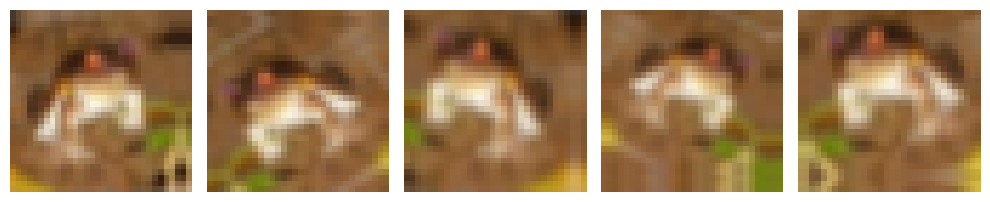

Experimento Baseline


c:\Users\Rocio\anaconda3\envs\DL_DuocUC_JM\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


CNN BASELINE
Filtros            : (32, 64)
Neuronas           : 128
Dropout Conv       : 0.3
Dropout Dense      : 0.5
L2                 : 0.0001
Learning Rate      : 0.001


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,118,090 (8.08 MB)

 Trainable params: 2,118,026 (8.08 MB)

 Non-trainable params: 64 (256.00 B)

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 67s 104ms/step - accuracy: 0.1018 - loss: 2.3929 - val_accuracy: 0.0980 - val_loss: 2.3194
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 63s 101ms/step - accuracy: 0.0988 - loss: 2.3185 - val_accuracy: 0.0977 - val_loss: 2.3174
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 81s 129ms/step - accuracy: 0.0995 - loss: 2.3164 - val_accuracy: 0.0977 - val_loss: 2.3153
Epoch 4/20
514/625 ━━━━━━━━━━━━━━━━━━━━ 10s 99ms/step - accuracy: 0.1038 - loss: 2.3146

In [ ]:
configuraciones = [

    {
        # Configuracion baseline
    },

    {
        # Configuracion experimento 1
    },

    {
        # Configuracion experimento 2
    },

    {
        # Configuracion experimento 3
    }

]

# ======================================================
# Ejecutar el proceso de optimización
# ======================================================

x_train, y_train, x_test, y_test, class_names = cargar_datos()
x_train, y_train, x_test, y_test, data_aug = preprocesar(x_train, y_train,x_test,y_test)


mejor_modelo, mejor_configuracion, resultados = optimizar_modelo(
    x_train,y_train,x_test,y_test,class_names,configuraciones
)

In [ ]:
# ======================================================
# Comparación de experimentos
# ======================================================


# ======================================================
# Identificar el mejor experimento
# ======================================================



# ======================================================
# Comparación gráfica
# ======================================================



# Parte V. Comparación de experimentos

Complete automáticamente una tabla como la siguiente.

| Experimento | LR | Batch | Dropout | Accuracy | Precision | Recall | F1 | Tiempo |
|-------------|----|--------|----------|----------|-----------|--------|----|---------|
| E1 | | | | | | | | |
| E2 | | | | | | | | |
| E3 | | | | | | | | |



# Parte VI. Reflexión final

Responda utilizando la evidencia obtenida durante la actividad.

1. ¿Qué experimento obtuvo el mejor desempeño general?

2. ¿Qué hiperparámetro produjo el mayor impacto sobre el modelo?

3. ¿Existen diferencias importantes entre Accuracy y F1 Score? Justifique.

4. ¿Las curvas de aprendizaje muestran evidencia de overfitting o underfitting?

5. ¿Grad-CAM evidencia cambios en las regiones de atención del modelo?

6. ¿Qué configuración seleccionaría para un escenario real? Justifique utilizando toda la evidencia obtenida durante el proceso de optimización.
